#GOES X-Ray Data

## Activity 1: Introduction to PySPEDAS

The Python-based Space Physics Environment Data Analysis Software ([PySPEDAS](https://pypi.org/project/pyspedas/)). This Python package provides a framework supporting multi-mission, multi-instrument retrieval, analysis, and visualization of heliophysics time series data.

The PySPEDAS package contains both general utility functions for data analysis and visualization and functions specific to each mission included.
* *Visit the link above and discuss the missions listed in your group. Share what youknow about a few of them. Identify two that none of you are familiar with and look them up as well.*


### 0) Load needed packages

In [1]:
!pip install pyspedas &> /dev/null #suppressed output

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pyspedas
from pyspedas import get_data
from pyspedas import tplot

### GOES X-Ray DATA
The GOES program is a series of spacecraft that have been continously operating starting from 1975 that are primarily used to monitor terrestial weather, but recent spacecraft (since the 1990's) have also had space evironment monitors. The [most recent GOES spacecraft](https://www.ncei.noaa.gov/products/satellite/goes-r) are documented here.  Wikipedia has a [list of all GOES Spacecraft](https://en.wikipedia.org/wiki/List_of_GOES_satellites) with operational dates. The GOES mission is a joint venture by NOAA and NASA.

PySPEDAS documentation provides a list [list of GOES Instrument](https://pyspedas.readthedocs.io/en/latest/goes.html#geostationary-operational-environmental-satellite-goes) available for data access. We will be using GOES-18 data here but we could use data from other GOES spacecraft.

For data prior to 2017 (GOES-15 or lower), the instrument list is different.

For X-ray data we will use the X-Ray sensor ('xrs') on the [GOES EXIS instrument](https://www.ncei.noaa.gov/products/goes-r-extreme-ultraviolet-xray-irradiance). The cell below sets the the *time interval*, *GOES probe number*, and *instrument*.

In [3]:
trange=['2024-05-07/00:00:00','2024-05-09/00:00:00'] #Date and time range for the data
probe = 18
instrument = 'xrs'

The next cell loads the data and outputs the data variables available.

In [4]:
from pyspedas.projects.goes import load
vars = load(trange=trange, probe=probe, instrument=instrument, datatype='1min', time_clip=True)
print(vars)

27-May-26 01:09:08: Downloading remote index: https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/
27-May-26 01:09:09: Downloading https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/sci_xrsf-l2-avg1m_g18_d20240507_v2-2-1.nc to goes_data/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/sci_xrsf-l2-avg1m_g18_d20240507_v2-2-1.nc
27-May-26 01:09:09: Download of goes_data/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/sci_xrsf-l2-avg1m_g18_d20240507_v2-2-1.nc complete, 0.287 MB in 0.1 sec (2.903 MB/sec) (transfer_normal)
27-May-26 01:09:10: Downloading https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/sci_xrsf-l2-avg1m_g18_d20240508_v2-2-1.nc to goes_data/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/sci_xrsf-l2-avg1m_g18_d20240508_v2-2-1.nc
27-May-26 01:09:10: Download of goes_data/goes18/l2/d

['g18_xrs_au_factor', 'g18_xrs_corrected_current_xrsb2', 'g18_xrs_electron_correction_flag', 'g18_xrs_roll_angle', 'g18_xrs_time', 'g18_xrs_xrs_primary_chan', 'g18_xrs_xrsa1_flag', 'g18_xrs_xrsa1_flag_excluded', 'g18_xrs_xrsa1_flux', 'g18_xrs_xrsa1_flux_electrons', 'g18_xrs_xrsa1_flux_observed', 'g18_xrs_xrsa1_num', 'g18_xrs_xrsa2_flag', 'g18_xrs_xrsa2_flag_excluded', 'g18_xrs_xrsa2_flux', 'g18_xrs_xrsa2_flux_electrons', 'g18_xrs_xrsa2_flux_observed', 'g18_xrs_xrsa2_num', 'g18_xrs_xrsa_flag', 'g18_xrs_xrsa_flag_excluded', 'g18_xrs_xrsa_flux', 'g18_xrs_xrsa_flux_electrons', 'g18_xrs_xrsa_flux_observed', 'g18_xrs_xrsa_num', 'g18_xrs_xrsb1_flag', 'g18_xrs_xrsb1_flag_excluded', 'g18_xrs_xrsb1_flux', 'g18_xrs_xrsb1_flux_electrons', 'g18_xrs_xrsb1_flux_observed', 'g18_xrs_xrsb1_num', 'g18_xrs_xrsb2_flag', 'g18_xrs_xrsb2_flag_excluded', 'g18_xrs_xrsb2_flux', 'g18_xrs_xrsb2_flux_electrons', 'g18_xrs_xrsb2_flux_observed', 'g18_xrs_xrsb2_num', 'g18_xrs_xrsb_flag', 'g18_xrs_xrsb_flag_excluded', '

Note that the list of variables is provides in 'vars'. For our purposes we will just use 'g18_xrs_xrsa_flux'.
The next cell plots that data.  

27-May-26 01:09:22: Downloading remote index: https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/
27-May-26 01:09:23: /usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

27-May-26 01:09:23: File is current: goes_data/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/sci_xrsf-l2-avg1m_g18_d20240507_v2-2-1.nc
27-May-26 01:09:34: /usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

27-May-26 01:09

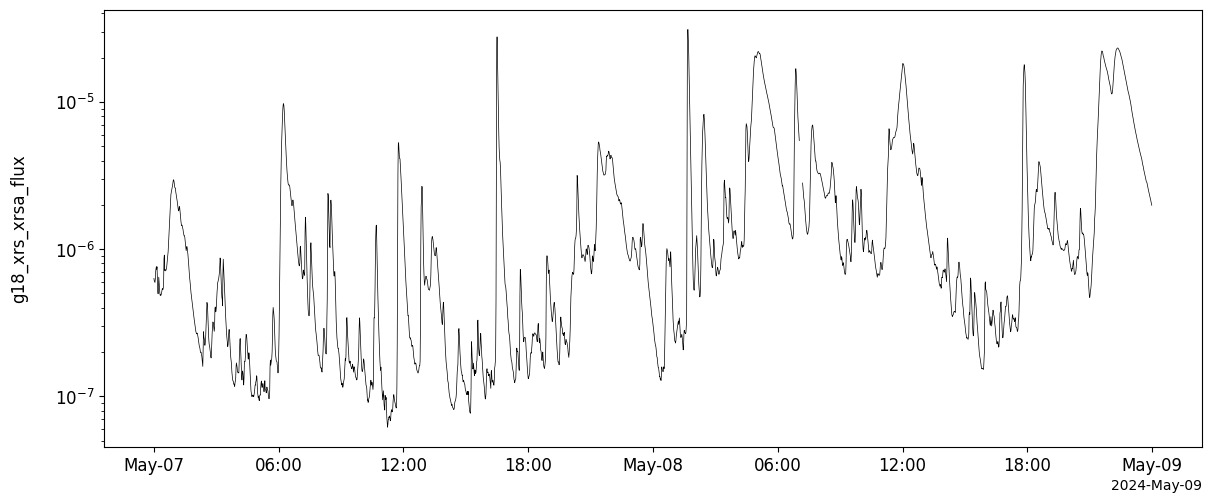

In [5]:
pyspedas.projects.goes.xrs(probe=probe,trange=trange)
pyspedas.options('g18_xrs_xrsa_flux', 'ylog', 1)
pyspedas.tplot(['g18_xrs_xrsa_flux'])

### X-Ray Flare Classification
Use the [GOES X-Ray classification scheme](https://hdrl.gsfc.nasa.gov/LWS_Space_Weather/GOES_Xray_descrip.html) to classify the flares in this data set.
- How many 'M' class flares do you see? 'X' Class?
- Expand the time interval around this time and replot the data.
- Make a table of times for the 'M' and 'X' flares you see.   
- Narrow down the date range to get the specific time for an X-class flare.  

27-May-26 01:09:55: Downloading remote index: https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/
27-May-26 01:09:56: /usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

27-May-26 01:09:56: Downloading https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/sci_xrsf-l2-avg1m_g18_d20240510_v2-2-1.nc to goes_data/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/sci_xrsf-l2-avg1m_g18_d20240510_v2-2-1.nc
27-May-26 01:10:07: Download of goes_data/goes18/l2/data/xrsf-l2-avg1m_science/2024/05/sci_xrsf-l2-avg1m_g18_d20240510_v2-2-1.nc complete, 0.287 MB in 10.1 sec (0.028 MB/sec) (transfer_slow)
27-May

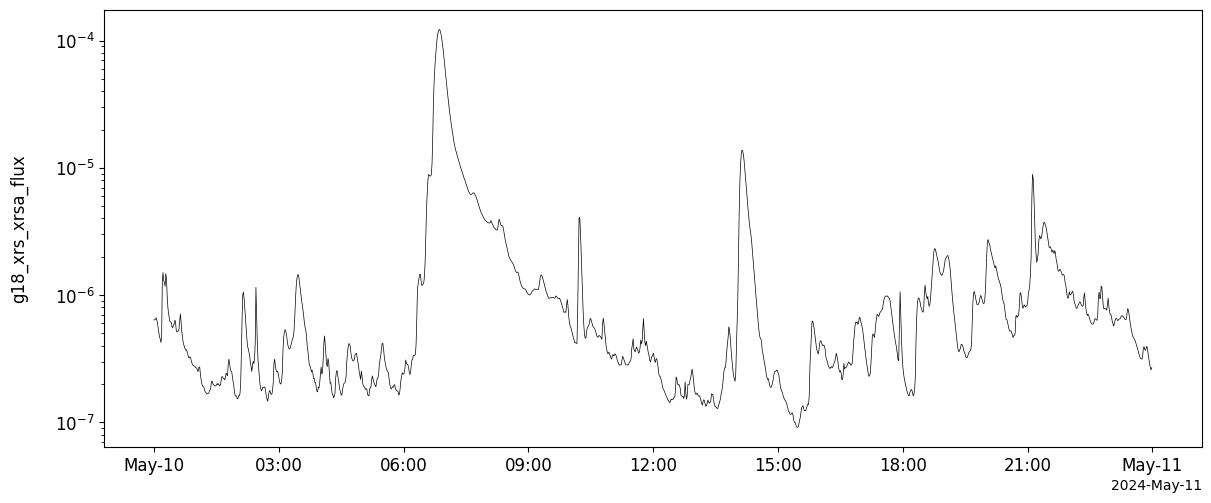

In [6]:
trange=['2024-05-10/00:00:00','2024-05-11/00:00:00'] #Date and time range for the data
vars = load(trange=trange, probe=probe, instrument=instrument, datatype='1min', time_clip=True)
pyspedas.projects.goes.xrs(probe=probe,trange=trange)
pyspedas.options('g18_xrs_xrsa_flux', 'ylog', 1)
pyspedas.tplot(['g18_xrs_xrsa_flux'])

##Getting the Data (Skip if time constrained)
For this activity you don't need to convert the data into variables you can use but you using the cell below. The PySPEDAS 'get_data' function returns an object with "time" and "y" attributes representing the time series for this data set.

In [7]:
data = get_data('g18_xrs_xrsa_flux', dt=True)
print(min(data.y), max(data.y))

9.163941e-08 0.00012202067


### Discuss
Notice that the minimum value of the X-Ray data is negative.  - Since this is suppose to represent a flux, do negative values make sense?

'-9999.00' is inserted into the data when there are issues with the data such as spacecraft communications. The cell below removes these.

In [8]:
mask = data.y<0
t = data.times[~mask]
y=data.y[~mask]
print(min(y), max(y))

9.163941e-08 0.00012202067


The next cell plots the masked data

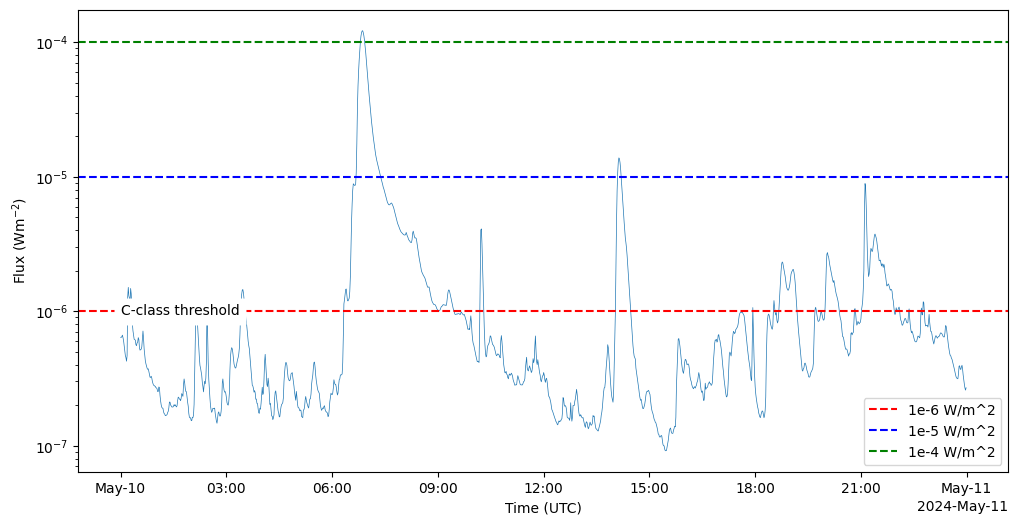

In [9]:
fig, ax = plt.subplots(figsize=(12,6))
ax.set_yscale('log')
ax.plot(t,y,lw=0.5)
ax.set_xlabel('Time (UTC)')
ax.set_ylabel('Flux (Wm$^{-2}$)')

# Add a horizontal line and label
ax.axhline(1e-6, color='red', linestyle='--', label='1e-6 W/m^2')
ax.text(t[0], 1e-6, 'C-class threshold', va='center', ha='left', backgroundcolor='w')
ax.legend()

ax.axhline(1e-5, color='blue', linestyle='--', label='1e-5 W/m^2')
ax.text(t[0], 1e-6, 'C-class threshold', va='center', ha='left', backgroundcolor='w')
ax.legend()

ax.axhline(1e-4, color='green', linestyle='--', label='1e-4 W/m^2')
ax.text(t[0], 1e-6, 'C-class threshold', va='center', ha='left', backgroundcolor='w')
ax.legend()

# Copy the code above and set the lines for M and X class flares.

plt.show()